Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda
GPU: Tesla T4
GPU Memory: 14.56 GB

Extracting dataset...
Extraction complete.

Dataset structure found:
Train: /content/train
Valid: /content/valid
Test : /content/test

TRAIN:
  autistic: 1263 images
  non_autistic: 1263 images

VALID:
  autistic: 100 images
  non_autistic: 100 images

TEST:
  autistic: 100 images
  non_autistic: 100 images

Class mapping:
{'autistic': 0, 'non_autistic': 1}

Dataset sizes:
Train: 2526
Valid: 200
Test : 200

Loading pretrained ResNet50...
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 176MB/s]



No previous checkpoint found.
Starting training from epoch 1.

PHASE 2 TRAINING
Epochs this session: 1 -> 10
Total dataset images: 2926

Epoch 1/10
Train Loss: 0.5071 | Train Acc: 74.11%
Val Loss: 0.4229 | Val Acc: 82.50%
Val Macro F1: 0.8243 | Val Weighted F1: 0.8243
LR: 1.00e-04 | Time: 0.69 min
>>> BEST MODEL SAVED
Checkpoint saved.

Epoch 2/10
Train Loss: 0.3365 | Train Acc: 85.04%
Val Loss: 0.4057 | Val Acc: 83.50%
Val Macro F1: 0.8343 | Val Weighted F1: 0.8343
LR: 1.00e-04 | Time: 0.34 min
>>> BEST MODEL SAVED
Checkpoint saved.

Epoch 3/10
Train Loss: 0.2374 | Train Acc: 90.34%
Val Loss: 0.3700 | Val Acc: 86.00%
Val Macro F1: 0.8600 | Val Weighted F1: 0.8600
LR: 1.00e-04 | Time: 0.36 min
>>> BEST MODEL SAVED
Checkpoint saved.

Epoch 4/10
Train Loss: 0.1567 | Train Acc: 93.67%
Val Loss: 0.3681 | Val Acc: 83.50%
Val Macro F1: 0.8347 | Val Weighted F1: 0.8347
LR: 1.00e-04 | Time: 0.34 min
>>> BEST MODEL SAVED
Checkpoint saved.

Epoch 5/10
Train Loss: 0.1250 | Train Acc: 95.29%
Val 

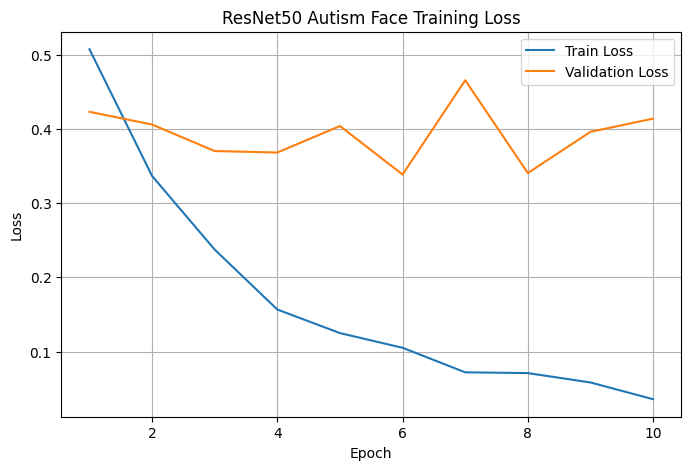

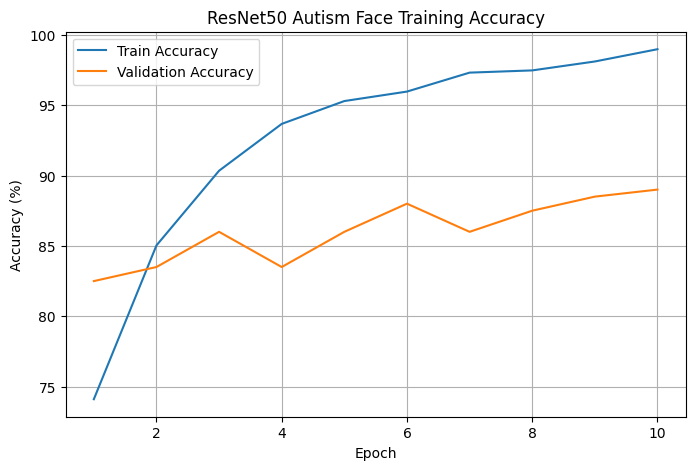


Loading best ResNet50 model...
Best model loaded from:
/content/drive/MyDrive/NeuroScreen/models/autism_face_best.pth

FINAL TEST EVALUATION
Test Loss: 0.3568
Test Accuracy: 85.50%
Test Macro F1: 0.8539
Test Weighted F1: 0.8539

Classification Report:
              precision    recall  f1-score   support

    autistic     0.9277    0.7700    0.8415       100
non_autistic     0.8034    0.9400    0.8664       100

    accuracy                         0.8550       200
   macro avg     0.8656    0.8550    0.8539       200
weighted avg     0.8656    0.8550    0.8539       200



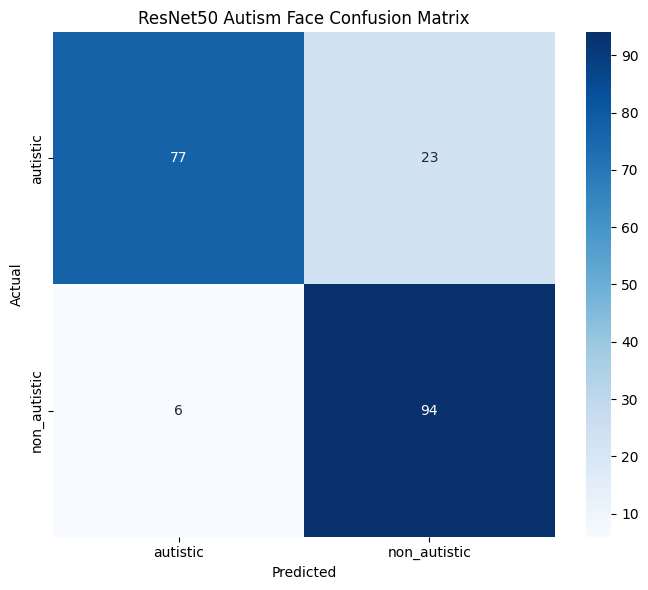


PHASE 2 COMPLETE
Test Accuracy : 85.50%
Macro F1      : 0.8539
Weighted F1   : 0.8539

Files saved:
Checkpoint: /content/drive/MyDrive/NeuroScreen/checkpoints/autism_checkpoint.pth
Best Model: /content/drive/MyDrive/NeuroScreen/models/autism_face_best.pth
History: /content/drive/MyDrive/NeuroScreen/results/autism_training_history.csv
Report: /content/drive/MyDrive/NeuroScreen/results/autism_classification_report.txt
Confusion Matrix: /content/drive/MyDrive/NeuroScreen/results/autism_confusion_matrix.png
Metrics: /content/drive/MyDrive/NeuroScreen/results/autism_final_metrics.json


In [ ]:
# ============================================================
# NEUROSCREEN - PHASE 2
# DATASET 2: AUTISTIC CHILDREN FACIAL IMAGE DATASET
# MODEL: RESNET50
# ============================================================

# -----------------------------
# 1. INSTALL REQUIRED PACKAGES
# -----------------------------
!pip -q install scikit-learn seaborn


# -----------------------------
# 2. IMPORTS
# -----------------------------
import os
import json
import random
import zipfile
import shutil
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

from torchvision import datasets, transforms, models
from torchvision.models import ResNet50_Weights

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    f1_score
)

from google.colab import drive


# -----------------------------
# 3. MOUNT GOOGLE DRIVE
# -----------------------------
drive.mount('/content/drive')


# ============================================================
# 4. CONFIGURATION
# ============================================================

BASE = "/content/drive/MyDrive/NeuroScreen"

# Dataset ZIP
ZIP_PATH = "/content/drive/MyDrive/NeuroScreen/Autistic Children Facial Image Dataset.zip"

# Local extraction directory
LOCAL_DATASET = "/content/AutismFace"

# Drive directories
CHECKPOINT_DIR = os.path.join(BASE, "checkpoints")
MODEL_DIR = os.path.join(BASE, "models")
RESULT_DIR = os.path.join(BASE, "results")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

# Files
CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR,
    "autism_checkpoint.pth"
)

BEST_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "autism_face_best.pth"
)

HISTORY_PATH = os.path.join(
    RESULT_DIR,
    "autism_training_history.csv"
)

REPORT_PATH = os.path.join(
    RESULT_DIR,
    "autism_classification_report.txt"
)

CONFUSION_PATH = os.path.join(
    RESULT_DIR,
    "autism_confusion_matrix.png"
)

METRICS_PATH = os.path.join(
    RESULT_DIR,
    "autism_final_metrics.json"
)

# Training settings
IMAGE_SIZE = 224
BATCH_SIZE = 32
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

# IMPORTANT:
# One Colab session = 10 epochs
EPOCHS_PER_SESSION = 10

NUM_WORKERS = 2

SEED = 42


# ============================================================
# 5. REPRODUCIBILITY
# ============================================================

def set_seed(seed=42):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark = True


set_seed(SEED)


# ============================================================
# 6. DEVICE
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU Memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory / 1024**3,
            2
        ),
        "GB"
    )


# ============================================================
# 7. EXTRACT DATASET
# ============================================================

if not os.path.exists(LOCAL_DATASET):

    print("\nExtracting dataset...")

    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall("/content")

    print("Extraction complete.")

else:

    print("\nDataset already extracted:")
    print(LOCAL_DATASET)

# ============================================================
# 8. DATASET LOCATION
# ============================================================

# Your ZIP extracted train/valid/test directly into /content

DATASET_ROOT = "/content"

TRAIN_DIR = "/content/train"
VALID_DIR = "/content/valid"
TEST_DIR  = "/content/test"

print("\nDataset structure found:")

print("Train:", TRAIN_DIR)
print("Valid:", VALID_DIR)
print("Test :", TEST_DIR)


# ============================================================
# 9. VERIFY CLASS DIRECTORIES
# ============================================================

EXPECTED_CLASSES = ["autistic", "non_autistic"]

for split_name, split_dir in [
    ("TRAIN", TRAIN_DIR),
    ("VALID", VALID_DIR),
    ("TEST", TEST_DIR)
]:

    print(f"\n{split_name}:")

    for cls in EXPECTED_CLASSES:

        cls_path = os.path.join(
            split_dir,
            cls
        )

        if not os.path.isdir(cls_path):

            raise FileNotFoundError(
                f"Missing class directory: {cls_path}"
            )

        # Count JPG/JPEG/PNG files
        image_count = 0

        for filename in os.listdir(cls_path):

            if filename.lower().endswith(
                (".jpg", ".jpeg", ".png")
            ):
                image_count += 1

        print(
            f"  {cls}: {image_count} images"
        )


# ============================================================
# 10. DATA TRANSFORMS
# ============================================================

# Training augmentation
train_transform = transforms.Compose([

    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),

    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.RandomRotation(
        degrees=10
    ),

    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# Validation / test transform
eval_transform = transforms.Compose([

    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ============================================================
# 11. LOAD DATASETS
# ============================================================

train_dataset = datasets.ImageFolder(
    TRAIN_DIR,
    transform=train_transform
)

valid_dataset = datasets.ImageFolder(
    VALID_DIR,
    transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    TEST_DIR,
    transform=eval_transform
)


print("\nClass mapping:")
print(train_dataset.class_to_idx)

print("\nDataset sizes:")
print("Train:", len(train_dataset))
print("Valid:", len(valid_dataset))
print("Test :", len(test_dataset))


# ============================================================
# 12. DATALOADERS
# ============================================================

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)


# ============================================================
# 13. BUILD RESNET50
# ============================================================

print("\nLoading pretrained ResNet50...")

weights = ResNet50_Weights.DEFAULT

model = models.resnet50(
    weights=weights
)

# Replace final classifier
num_features = model.fc.in_features

model.fc = nn.Linear(
    num_features,
    2
)

model = model.to(device)


# ============================================================
# 14. LOSS + OPTIMIZER
# ============================================================

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)


# ============================================================
# 15. MIXED PRECISION
# ============================================================

use_amp = torch.cuda.is_available()

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=use_amp
)


# ============================================================
# 16. TRAINING FUNCTIONS
# ============================================================

def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    scaler,
    device
):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=use_amp
        ):

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

        scaler.scale(loss).backward()

        scaler.step(optimizer)

        scaler.update()

        running_loss += (
            loss.item() * images.size(0)
        )

        _, predicted = torch.max(
            outputs,
            1
        )

        total += labels.size(0)

        correct += (
            predicted == labels
        ).sum().item()

    epoch_loss = (
        running_loss / total
    )

    epoch_acc = (
        correct / total
    )

    return epoch_loss, epoch_acc


@torch.no_grad()
def evaluate(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    running_loss = 0.0

    all_labels = []
    all_predictions = []

    total = 0

    for images, labels in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=use_amp
        ):

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

        running_loss += (
            loss.item() * images.size(0)
        )

        total += images.size(0)

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

    epoch_loss = (
        running_loss / total
    )

    epoch_acc = accuracy_score(
        all_labels,
        all_predictions
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        all_labels,
        all_predictions,
        average="weighted",
        zero_division=0
    )

    return (
        epoch_loss,
        epoch_acc,
        macro_f1,
        weighted_f1
    )


# ============================================================
# 17. CHECKPOINT / HISTORY
# ============================================================

start_epoch = 0

history = []

best_val_loss = float("inf")

best_val_acc = 0.0


# ============================================================
# 18. RESUME CHECKPOINT IF AVAILABLE
# ============================================================

if os.path.exists(CHECKPOINT_PATH):

    print("\nExisting checkpoint found.")

    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location=device
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    optimizer.load_state_dict(
        checkpoint["optimizer_state_dict"]
    )

    scheduler.load_state_dict(
        checkpoint["scheduler_state_dict"]
    )

    start_epoch = checkpoint[
        "epoch"
    ] + 1

    best_val_loss = checkpoint.get(
        "best_val_loss",
        float("inf")
    )

    best_val_acc = checkpoint.get(
        "best_val_acc",
        0.0
    )

    history = checkpoint.get(
        "history",
        []
    )

    print(
        f"Resuming from epoch {start_epoch}"
    )

    print(
        f"Previous best validation loss: "
        f"{best_val_loss:.4f}"
    )

else:

    print(
        "\nNo previous checkpoint found."
    )

    print(
        "Starting training from epoch 1."
    )


# ============================================================
# 19. TRAIN FOR NEXT 10 EPOCHS
# ============================================================

end_epoch = start_epoch + EPOCHS_PER_SESSION

print("\n========================================")
print("PHASE 2 TRAINING")
print("========================================")

print(
    f"Epochs this session: "
    f"{start_epoch + 1} -> {end_epoch}"
)

print(
    f"Total dataset images: "
    f"{len(train_dataset) + len(valid_dataset) + len(test_dataset)}"
)

session_start = time.time()


for epoch in range(
    start_epoch,
    end_epoch
):

    epoch_start = time.time()

    print(
        f"\nEpoch {epoch + 1}/{end_epoch}"
    )

    # -------------------------
    # TRAIN
    # -------------------------

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        scaler,
        device
    )

    # -------------------------
    # VALIDATION
    # -------------------------

    val_loss, val_acc, val_macro_f1, val_weighted_f1 = evaluate(
        model,
        valid_loader,
        criterion,
        device
    )

    # -------------------------
    # LR SCHEDULER
    # -------------------------

    scheduler.step(
        val_loss
    )

    current_lr = optimizer.param_groups[0]["lr"]

    # -------------------------
    # SAVE HISTORY
    # -------------------------

    history.append({

        "epoch": epoch + 1,

        "train_loss": train_loss,

        "train_accuracy": train_acc,

        "val_loss": val_loss,

        "val_accuracy": val_acc,

        "val_macro_f1": val_macro_f1,

        "val_weighted_f1": val_weighted_f1,

        "learning_rate": current_lr

    })

    # -------------------------
    # PRINT
    # -------------------------

    elapsed = time.time() - epoch_start

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc*100:.2f}%"
    )

    print(
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc*100:.2f}%"
    )

    print(
        f"Val Macro F1: {val_macro_f1:.4f} | "
        f"Val Weighted F1: {val_weighted_f1:.4f}"
    )

    print(
        f"LR: {current_lr:.2e} | "
        f"Time: {elapsed/60:.2f} min"
    )

    # ========================================================
    # SAVE BEST MODEL
    # ========================================================

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_val_acc = val_acc

        torch.save(
            {
                "model_state_dict":
                    model.state_dict(),

                "class_to_idx":
                    train_dataset.class_to_idx,

                "val_loss":
                    val_loss,

                "val_accuracy":
                    val_acc,

                "val_macro_f1":
                    val_macro_f1,

                "val_weighted_f1":
                    val_weighted_f1,

                "epoch":
                    epoch + 1
            },
            BEST_MODEL_PATH
        )

        print(
            ">>> BEST MODEL SAVED"
        )

    # ========================================================
    # SAVE CHECKPOINT
    # ========================================================

    torch.save(
        {
            "epoch":
                epoch,

            "model_state_dict":
                model.state_dict(),

            "optimizer_state_dict":
                optimizer.state_dict(),

            "scheduler_state_dict":
                scheduler.state_dict(),

            "best_val_loss":
                best_val_loss,

            "best_val_acc":
                best_val_acc,

            "history":
                history,

            "class_to_idx":
                train_dataset.class_to_idx
        },
        CHECKPOINT_PATH
    )

    print(
        "Checkpoint saved."
    )


session_time = (
    time.time() - session_start
)

print("\n========================================")
print("SESSION COMPLETE")
print("========================================")

print(
    f"Session time: "
    f"{session_time/60:.2f} minutes"
)

print(
    f"Best validation loss: "
    f"{best_val_loss:.4f}"
)

print(
    f"Best validation accuracy: "
    f"{best_val_acc*100:.2f}%"
)


# ============================================================
# 20. SAVE TRAINING HISTORY
# ============================================================

history_df = pd.DataFrame(history)

history_df.to_csv(
    HISTORY_PATH,
    index=False
)

print(
    "\nTraining history saved:"
)

print(HISTORY_PATH)


# ============================================================
# 21. SAVE CLASS MAPPING
# ============================================================

CLASS_MAPPING_PATH = os.path.join(
    RESULT_DIR,
    "autism_class_mapping.json"
)

with open(
    CLASS_MAPPING_PATH,
    "w"
) as f:

    json.dump(
        train_dataset.class_to_idx,
        f,
        indent=4
    )


# ============================================================
# 22. PLOT TRAINING CURVES
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Train Loss"
)

plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "ResNet50 Autism Face Training Loss"
)

plt.legend()

plt.grid(True)

LOSS_CURVE_PATH = os.path.join(
    RESULT_DIR,
    "autism_loss_curve.png"
)

plt.savefig(
    LOSS_CURVE_PATH,
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 23. ACCURACY CURVE
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_accuracy"] * 100,
    label="Train Accuracy"
)

plt.plot(
    history_df["epoch"],
    history_df["val_accuracy"] * 100,
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")

plt.title(
    "ResNet50 Autism Face Training Accuracy"
)

plt.legend()

plt.grid(True)

ACC_CURVE_PATH = os.path.join(
    RESULT_DIR,
    "autism_accuracy_curve.png"
)

plt.savefig(
    ACC_CURVE_PATH,
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 24. LOAD BEST MODEL
# ============================================================

print("\nLoading best ResNet50 model...")

best_checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device
)

model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

model = model.to(device)

print(
    "Best model loaded from:"
)

print(BEST_MODEL_PATH)


# ============================================================
# 25. FINAL TEST EVALUATION
# ============================================================

print("\n========================================")
print("FINAL TEST EVALUATION")
print("========================================")

test_loss, test_acc, test_macro_f1, test_weighted_f1 = evaluate(
    model,
    test_loader,
    criterion,
    device
)

print(
    f"Test Loss: {test_loss:.4f}"
)

print(
    f"Test Accuracy: {test_acc*100:.2f}%"
)

print(
    f"Test Macro F1: {test_macro_f1:.4f}"
)

print(
    f"Test Weighted F1: {test_weighted_f1:.4f}"
)


# ============================================================
# 26. GET TEST PREDICTIONS
# ============================================================

@torch.no_grad()
def get_predictions(
    model,
    loader,
    device
):

    model.eval()

    all_labels = []
    all_predictions = []

    all_probabilities = []

    for images, labels in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=use_amp
        ):

            outputs = model(images)

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        predictions = torch.argmax(
            probabilities,
            dim=1
        )

        all_labels.extend(
            labels.numpy()
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_probabilities.extend(
            probabilities.cpu().numpy()
        )

    return (
        np.array(all_labels),
        np.array(all_predictions),
        np.array(all_probabilities)
    )


y_true, y_pred, y_prob = get_predictions(
    model,
    test_loader,
    device
)


# ============================================================
# 27. CLASSIFICATION REPORT
# ============================================================

class_names = [
    "autistic",
    "non_autistic"
]

report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4,
    zero_division=0
)

print("\nClassification Report:")
print(report)


with open(
    REPORT_PATH,
    "w"
) as f:

    f.write(report)


# ============================================================
# 28. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(
    figsize=(7, 6)
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel(
    "Predicted"
)

plt.ylabel(
    "Actual"
)

plt.title(
    "ResNet50 Autism Face Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    CONFUSION_PATH,
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 29. DETAILED METRICS
# ============================================================

precision_macro, recall_macro, f1_macro, _ = \
    precision_recall_fscore_support(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

precision_weighted, recall_weighted, f1_weighted, _ = \
    precision_recall_fscore_support(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )


final_metrics = {

    "model": "ResNet50",

    "dataset": "Autistic Children Facial Image Dataset",

    "test_images": int(len(y_true)),

    "test_loss": float(test_loss),

    "test_accuracy": float(test_acc),

    "macro_precision": float(
        precision_macro
    ),

    "macro_recall": float(
        recall_macro
    ),

    "macro_f1": float(
        f1_macro
    ),

    "weighted_precision": float(
        precision_weighted
    ),

    "weighted_recall": float(
        recall_weighted
    ),

    "weighted_f1": float(
        f1_weighted
    ),

    "best_validation_loss": float(
        best_checkpoint.get(
            "val_loss",
            best_val_loss
        )
    ),

    "best_validation_accuracy": float(
        best_checkpoint.get(
            "val_accuracy",
            best_val_acc
        )
    ),

    "class_mapping": train_dataset.class_to_idx
}


# ============================================================
# 30. SAVE FINAL METRICS
# ============================================================

with open(
    METRICS_PATH,
    "w"
) as f:

    json.dump(
        final_metrics,
        f,
        indent=4
    )


# ============================================================
# 31. FINAL SUMMARY
# ============================================================

print("\n========================================")
print("PHASE 2 COMPLETE")
print("========================================")

print(
    f"Test Accuracy : {test_acc*100:.2f}%"
)

print(
    f"Macro F1      : {f1_macro:.4f}"
)

print(
    f"Weighted F1   : {f1_weighted:.4f}"
)

print("\nFiles saved:")

print(
    "Checkpoint:",
    CHECKPOINT_PATH
)

print(
    "Best Model:",
    BEST_MODEL_PATH
)

print(
    "History:",
    HISTORY_PATH
)

print(
    "Report:",
    REPORT_PATH
)

print(
    "Confusion Matrix:",
    CONFUSION_PATH
)

print(
    "Metrics:",
    METRICS_PATH
)
